# 03 — Extração de features e EDA no espaço de features
Janelas de 5 s com 1 s de sobreposição (mesmo esquema da tese) → features espectrais, Hjorth e estatísticas por canal.
**19 canais de escalpo** (A1/A2, de orelha, excluídos — ver notebook 02), com nomes 10-20. As features vêm do
pipeline `v0` (`src/pipeline.py`: notch 60 Hz, 1–45 Hz, CAR, rejeição robusta de janelas por amplitude).
Gera `data/processed/features_windows.parquet` (nível janela) e `features_subjects.parquet` (nível participante).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

import mne
from src.data_io import load_metadata, PROCESSED_DIR, ROOT, SCALP_CHANNELS, REGION, mne_info
from src.pipeline import VARIANTS, build_features, load_variant
from src.features import feature_families
from src.evaluation import mann_whitney_fdr, icc1

FIG = ROOT / "reports" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
meta = load_metadata()

## Extração

In [2]:
if not (PROCESSED_DIR / "v0" / "features_windows.parquet").exists():
    build_features(VARIANTS["v0"], verbose=False)
feat_w, log = load_variant("v0")
rej = log[["subject", "group", "n_windows", "kept", "bad_channels"]].copy()
rej["kept_frac"] = rej.kept / rej.n_windows
feat_w.to_parquet(PROCESSED_DIR / "features_windows.parquet")
print(feat_w.shape)
rej.sort_values("kept_frac").head(10)

(2656, 384)


,subject,group,n_windows,kept,bad_channels,kept_frac
20,P23,CTR,10,8,NaN,0.800000
14,P15,TCM,12,10,NaN,0.833333
11,P12,CTR,167,146,F3,0.874251
24,P27,TCM,9,8,NaN,0.888889
16,P17,TCM,31,28,NaN,0.903226
32,P35,TCM,52,48,Pz,0.923077
2,P3,CTR,71,66,Fp1 Fp2,0.929577
33,P36,TCM,46,43,T4 P4,0.934783
12,P13,CTR,242,229,P4,0.946281
6,P7,CTR,78,74,O2,0.948718


> Rejeição robusta por participante (`src/windowing.reject_windows`): descarta janelas cuja amplitude (mediana entre
> canais do pico) é atípica para o próprio sujeito (z robusto > 3) ou > 500 µV. Um limiar fixo de 150 µV em todos os
> canais eliminava quase todas as janelas de vários participantes (fala durante o relato). ICA/ASR fica para depois.

In [3]:
ID_COLS = ["subject", "group", "sex", "window"]
FEATS = [c for c in feat_w.columns if c not in ID_COLS]
feat_s = feat_w.groupby(["subject", "group", "sex"])[FEATS].median().reset_index()
feat_s.to_parquet(PROCESSED_DIR / "features_subjects.parquet")
print(feat_s.shape, "| famílias:", feature_families(FEATS).unique().tolist())

(38, 383) | famílias: ['abs_delta', 'rel_delta', 'abs_theta', 'rel_theta', 'abs_alpha', 'rel_alpha', 'abs_beta', 'rel_beta', 'abs_gamma', 'rel_gamma', 'ratio_theta_alpha', 'ratio_theta_beta', 'spectral_entropy', 'peak_alpha_freq', 'hjorth_activity', 'hjorth_mobility', 'hjorth_complexity', 'std', 'skew', 'kurtosis']


## CTR × TCM por feature (nível participante)
Mann-Whitney + FDR. Com n=39, esperar pouca potência estatística: olhar tamanho de efeito (rank-biserial) além de q.
Também a média entre canais por família (menos testes, mais robusto).

In [4]:
fam = feature_families(FEATS)
feat_fam = pd.DataFrame({f: feat_s[fam.index[fam == f]].mean(axis=1) for f in fam.unique()})
res_fam = mann_whitney_fdr(feat_fam, feat_s["group"])
display(res_fam)
res_all = mann_whitney_fdr(feat_s[FEATS], feat_s["group"])
res_all.to_csv(ROOT / "reports" / "03_ctr_vs_tcm_features.csv", index=False)
res_all["canal"] = res_all.feature.str.split("__").str[1]
res_all["regiao"] = res_all.canal.map(REGION)
display(res_all.head(15))

,feature,median_CTR,median_TCM,rank_biserial,p,q_fdr
0,kurtosis,1.453647,2.089335,0.232493,0.228716,0.929788
1,abs_delta,1.778673,1.836479,0.176471,0.362773,0.929788
2,abs_alpha,0.715127,0.781659,0.137255,0.481066,0.929788
3,abs_theta,1.097576,1.382153,0.137255,0.481066,0.929788
4,ratio_theta_beta,2.435860,3.831389,0.137255,0.481066,0.929788
5,hjorth_mobility,0.186182,0.180121,-0.131653,0.499529,0.929788
6,rel_beta,0.121029,0.102743,-0.126050,0.518362,0.929788
7,hjorth_complexity,2.770229,3.057004,0.120448,0.537555,0.929788
8,hjorth_activity,2.065003,2.139910,0.098039,0.617721,0.929788
9,rel_theta,0.130629,0.132748,0.081232,0.681065,0.929788


,feature,median_CTR,median_TCM,rank_biserial,p,q_fdr,canal,regiao
0,kurtosis__P4,1.186143,2.427235,0.563025,0.003327,1.0,P4,parietal
1,skew__F4,-0.315564,-1.173683,-0.535014,0.005287,1.0,F4,frontal
2,ratio_theta_beta__F4,1.500587,4.412489,0.495798,0.009781,1.0,F4,frontal
3,rel_gamma__F4,0.014618,0.003040,-0.456583,0.017408,1.0,F4,frontal
4,rel_beta__F4,0.072469,0.022241,-0.450980,0.018843,1.0,F4,frontal
5,rel_theta__P3,0.117377,0.144569,0.428571,0.025668,1.0,P3,parietal
6,skew__P4,0.073452,0.253130,0.422969,0.027677,1.0,P4,parietal
7,skew__O1,0.182061,0.317412,0.417367,0.029819,1.0,O1,occipital
8,hjorth_mobility__F4,0.169970,0.095595,-0.406163,0.034535,1.0,F4,frontal
9,spectral_entropy__F4,0.627898,0.544274,-0.400560,0.037123,1.0,F4,frontal


### Topografia do tamanho de efeito CTR × TCM
Rank-biserial por canal (positivo = maior no TCM). Pontos brancos = p < 0,05 **sem correção** (nenhum sobrevive ao
FDR; os mapas servem para ver se os efeitos têm coerência espacial, não para afirmar diferença).

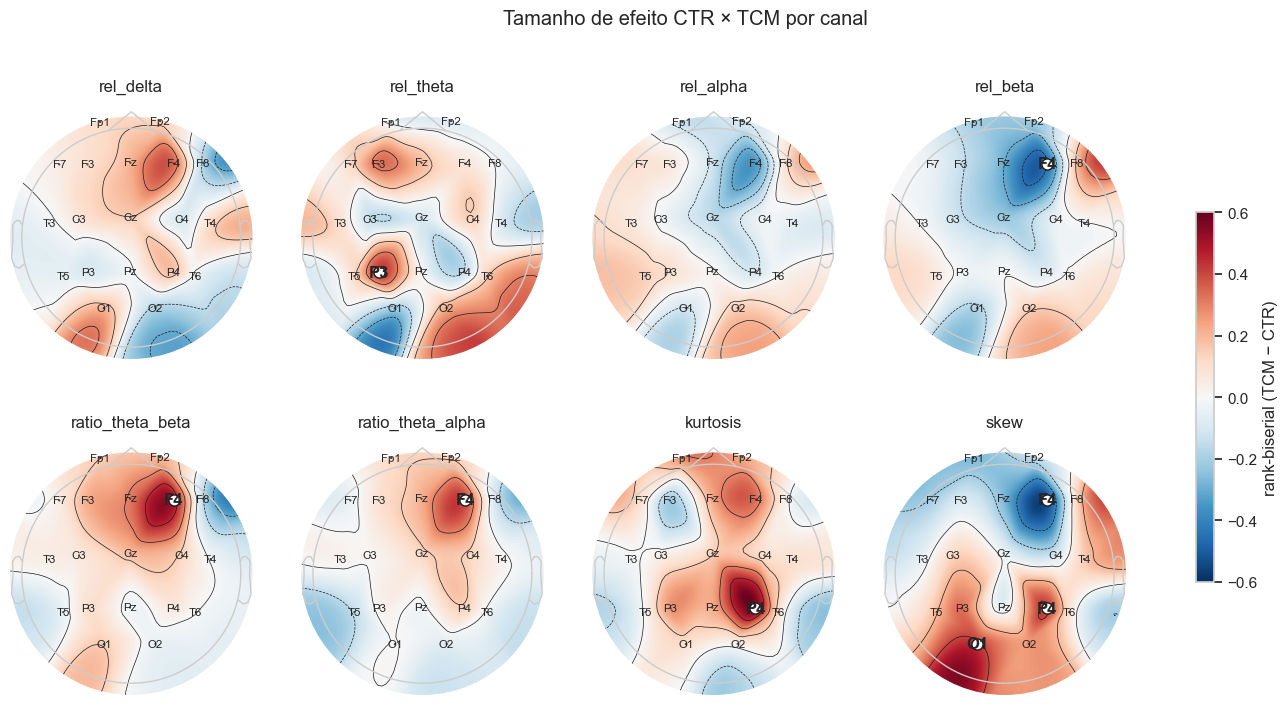

In [5]:
INFO = mne_info(SCALP_CHANNELS)
fams = ["rel_delta", "rel_theta", "rel_alpha", "rel_beta", "ratio_theta_beta", "ratio_theta_alpha", "kurtosis", "skew"]
eff = res_all.set_index("feature")
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, fm in zip(axes.ravel(), fams):
    r = np.array([eff.loc[f"{fm}__{c}", "rank_biserial"] for c in SCALP_CHANNELS])
    pv = np.array([eff.loc[f"{fm}__{c}", "p"] for c in SCALP_CHANNELS])
    im, _ = mne.viz.plot_topomap(r, INFO, axes=ax, show=False, cmap="RdBu_r", vlim=(-0.6, 0.6), names=SCALP_CHANNELS,
                                 mask=pv < 0.05, mask_params=dict(marker="o", markerfacecolor="w", markersize=8))
    ax.set_title(fm)
fig.colorbar(im, ax=axes, shrink=0.6, label="rank-biserial (TCM − CTR)")
fig.suptitle("Tamanho de efeito CTR × TCM por canal")
fig.savefig(FIG / "03_topo_efeito_grupo.png", dpi=120, bbox_inches="tight")

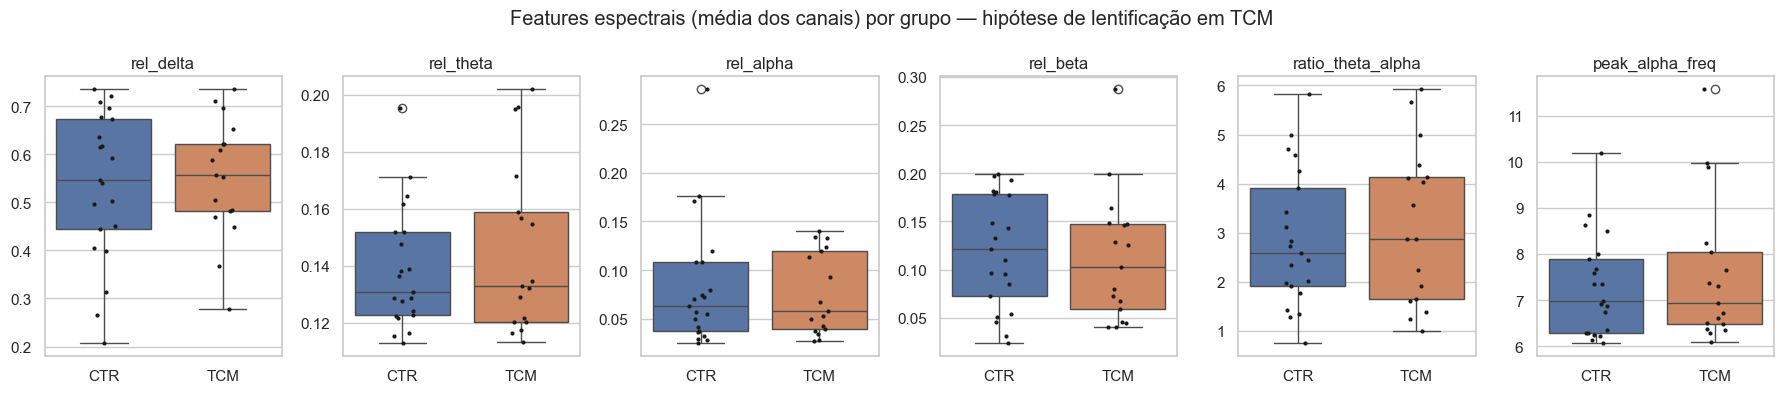

In [6]:
top = ["rel_delta", "rel_theta", "rel_alpha", "rel_beta", "ratio_theta_alpha", "peak_alpha_freq"]
fig, axes = plt.subplots(1, len(top), figsize=(18, 4))
for ax, f in zip(axes, top):
    sns.boxplot(x=feat_s.group, y=feat_fam[f], ax=ax, hue=feat_s.group, legend=False)
    sns.stripplot(x=feat_s.group, y=feat_fam[f], ax=ax, color="k", size=3)
    ax.set_title(f); ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Features espectrais (média dos canais) por grupo — hipótese de lentificação em TCM")
fig.tight_layout(); fig.savefig(FIG / "03_bandas_grupo.png", dpi=120)

## Redundância entre features

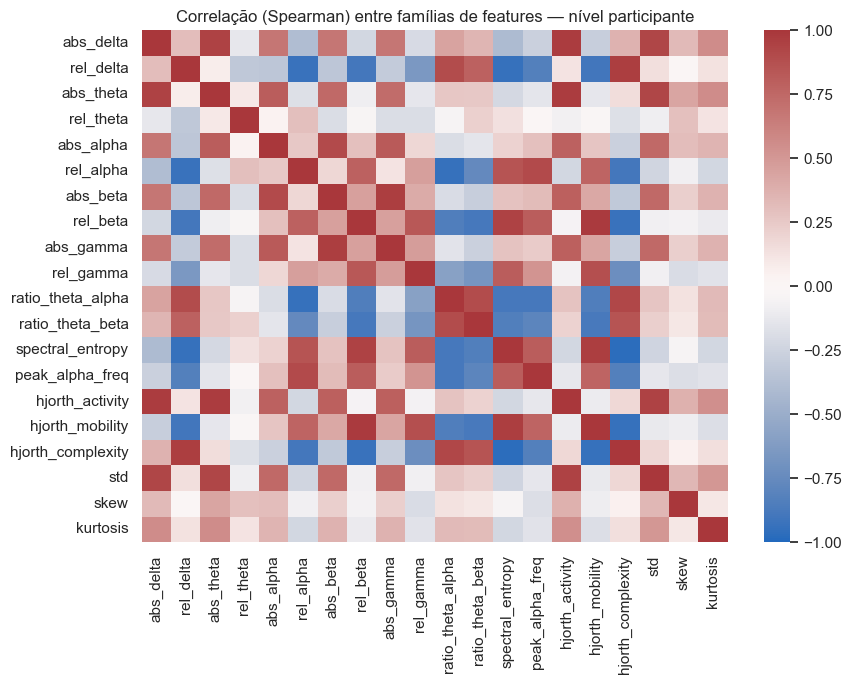

In [7]:
Cf = feat_fam.corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(Cf, cmap="vlag", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlação (Spearman) entre famílias de features — nível participante")
fig.tight_layout(); fig.savefig(FIG / "03_corr_features.png", dpi=120)

## Projeções 2D (nível janela)
Pergunta-chave: a estrutura dominante é **participante** (efeito indivíduo) ou **grupo**? Se as janelas formam
"ilhas" por sujeito, clusterizar janelas tende a achar pessoas, não diagnósticos → comparar com normalização
por participante (z-score dentro do sujeito).

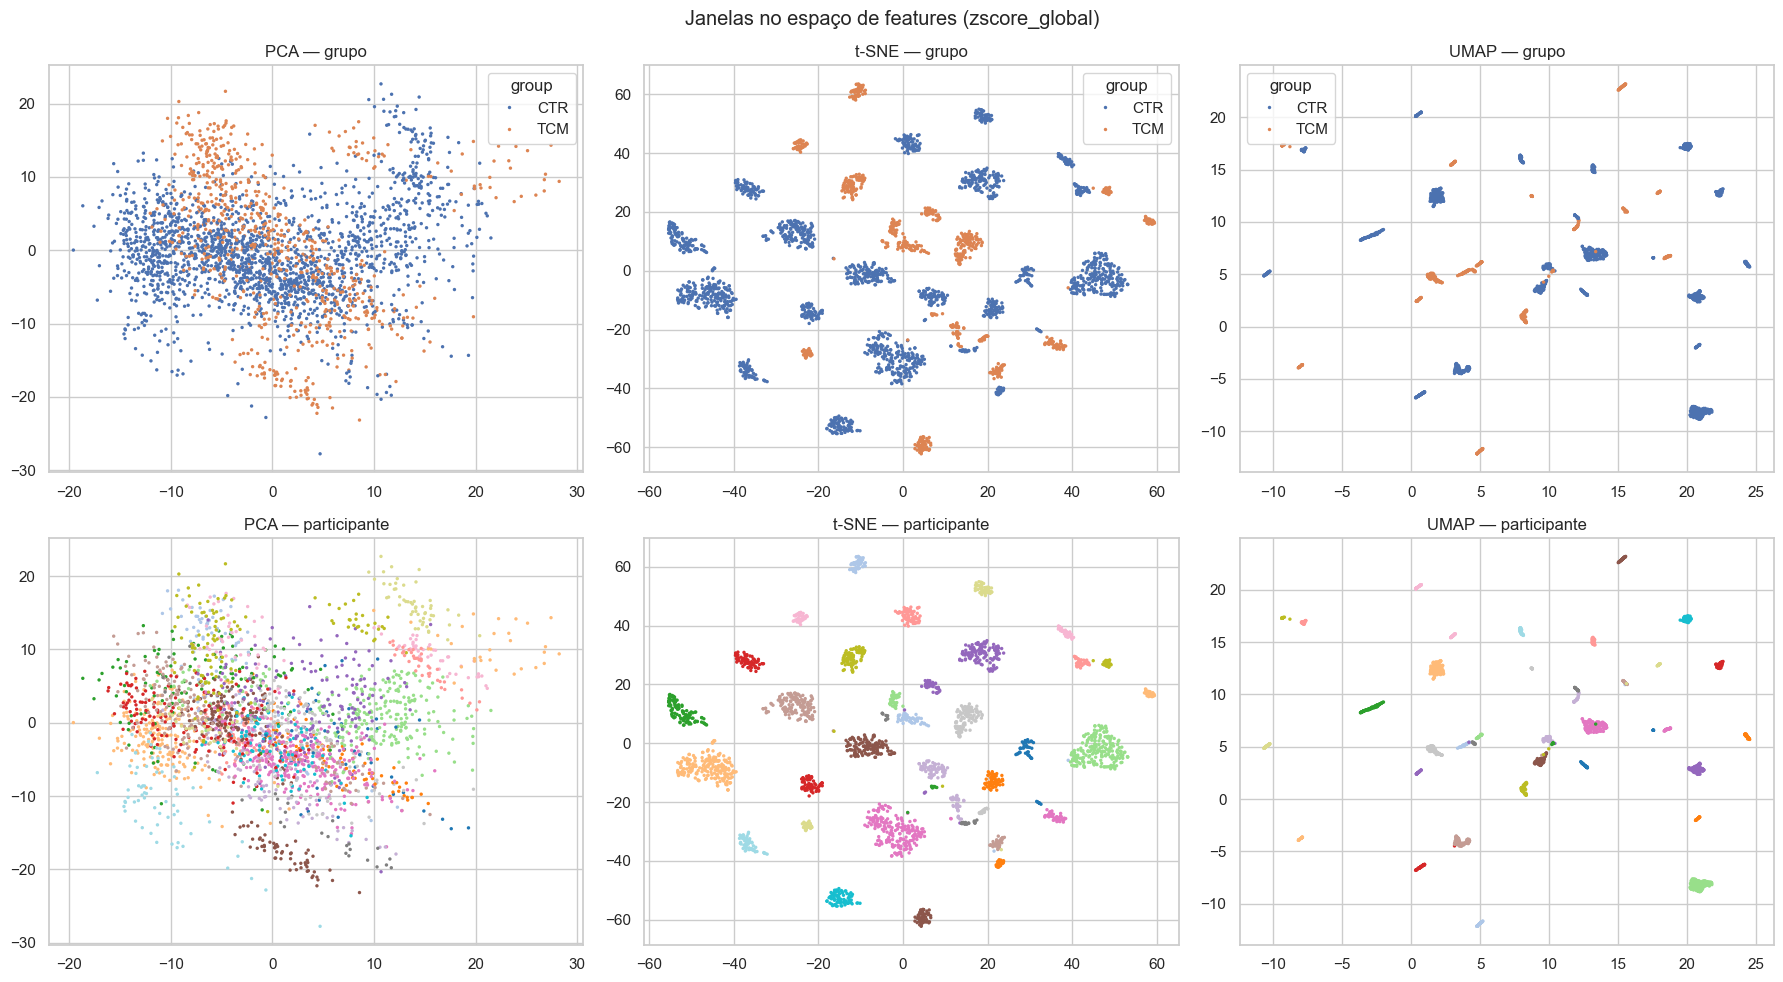

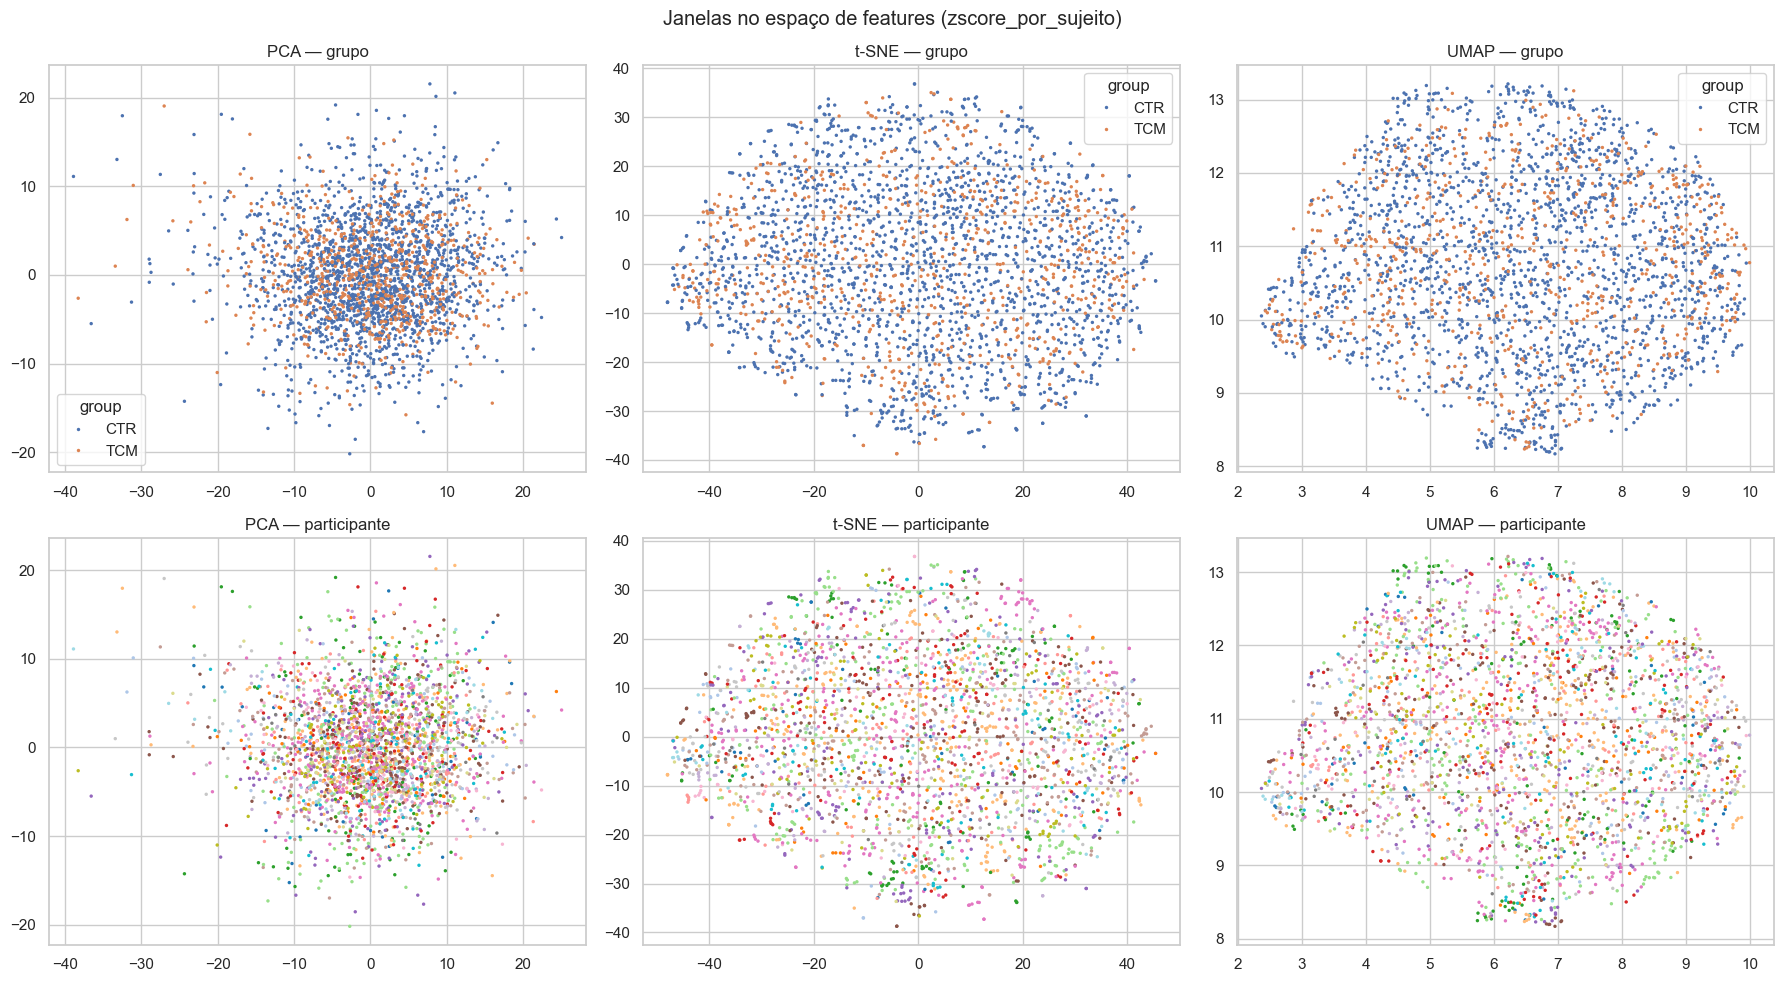

In [8]:
Xw = StandardScaler().fit_transform(feat_w[FEATS])
Xw_subj = feat_w.groupby("subject")[FEATS].transform(lambda c: (c - c.mean()) / (c.std() + 1e-9)).to_numpy()

def embed(X, seed=0):
    Z = PCA(n_components=min(50, X.shape[1]), random_state=seed).fit_transform(X)
    return {"PCA": Z[:, :2],
            "t-SNE": TSNE(n_components=2, perplexity=30, init="pca", random_state=seed).fit_transform(Z)}

try:
    import umap
    HAS_UMAP = True
except ImportError:
    HAS_UMAP = False
    print("umap-learn não instalado — pulando UMAP")

for name, X in [("zscore_global", Xw), ("zscore_por_sujeito", Xw_subj)]:
    E = embed(X)
    if HAS_UMAP:
        E["UMAP"] = umap.UMAP(random_state=0).fit_transform(X)
    fig, axes = plt.subplots(2, len(E), figsize=(6 * len(E), 10))
    for j, (ename, Z) in enumerate(E.items()):
        sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=feat_w.group, s=6, linewidth=0, ax=axes[0, j])
        axes[0, j].set_title(f"{ename} — grupo")
        sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=feat_w.subject, s=6, linewidth=0, ax=axes[1, j], legend=False,
                        palette="tab20")
        axes[1, j].set_title(f"{ename} — participante")
    fig.suptitle(f"Janelas no espaço de features ({name})")
    fig.tight_layout(); fig.savefig(FIG / f"03_embed_{name}.png", dpi=110)

## Quanto da variância é "participante"?
ICC(1) por feature (ANOVA de um fator; `src/evaluation.icc1`): fração da variância das janelas explicada pelo
participante. Valores altos = feature muito individual ("impressão digital").

count    380.000000
mean       0.586059
std        0.188723
min        0.090167
25%        0.453242
50%        0.633190
75%        0.722530
max        0.919676
Name: ICC, dtype: float64


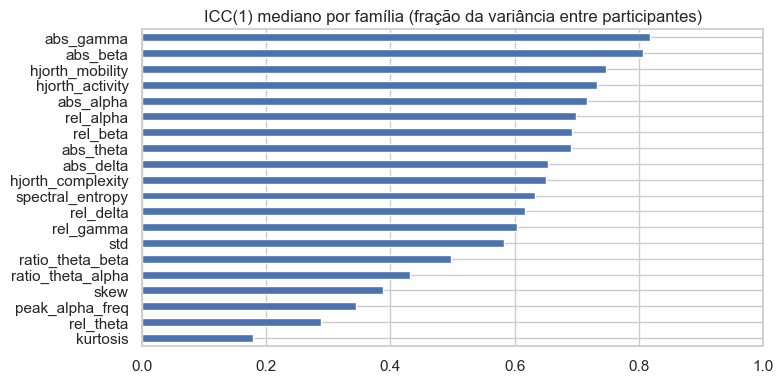

In [9]:
icc = icc1(feat_w[FEATS], feat_w.subject).rename("ICC")
print(icc.describe())
fig, ax = plt.subplots(figsize=(8, 4))
icc.groupby(feature_families(FEATS)).median().sort_values().plot.barh(ax=ax)
ax.set_xlim(0, 1); ax.set_title("ICC(1) mediano por família (fração da variância entre participantes)")
fig.tight_layout(); fig.savefig(FIG / "03_var_sujeito.png", dpi=120)

## PCA nível participante

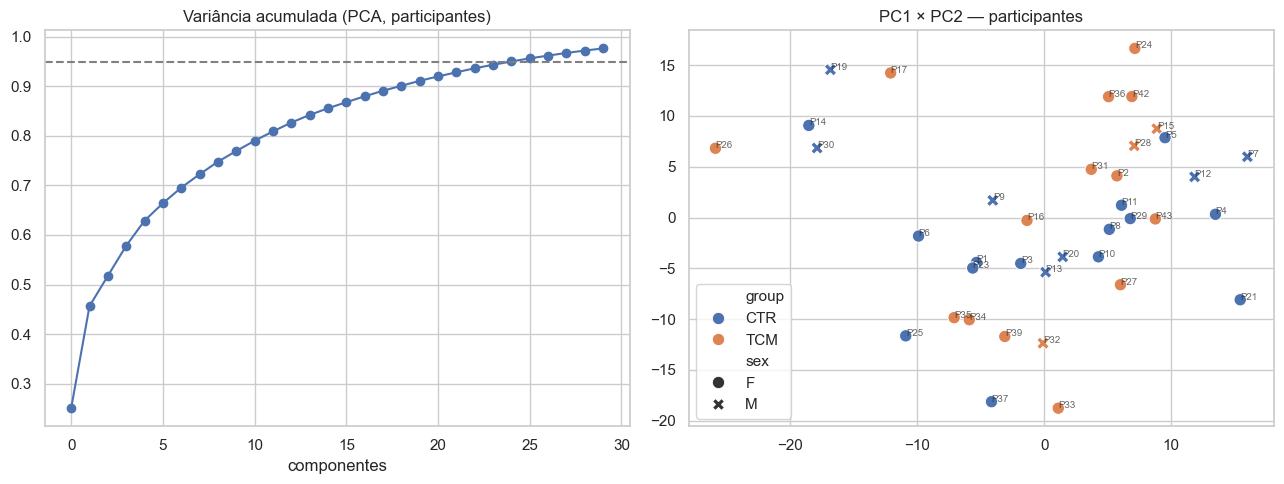

In [10]:
Xs = StandardScaler().fit_transform(feat_s[FEATS])
pca = PCA().fit(Xs)
Zs = pca.transform(Xs)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(np.cumsum(pca.explained_variance_ratio_[:30]), marker="o"); axes[0].axhline(0.95, ls="--", c="grey")
axes[0].set_title("Variância acumulada (PCA, participantes)"); axes[0].set_xlabel("componentes")
sns.scatterplot(x=Zs[:, 0], y=Zs[:, 1], hue=feat_s.group, style=feat_s.sex, s=80, ax=axes[1])
for i, s in enumerate(feat_s.subject):
    axes[1].annotate(s, Zs[i, :2], fontsize=7, alpha=0.7)
axes[1].set_title("PC1 × PC2 — participantes")
fig.tight_layout(); fig.savefig(FIG / "03_pca_sujeitos.png", dpi=120)